# Forward Euler and its piecewise linear interpolant

Companion notebook for Lecture 18 (`Lec18.tex`), producing `piecewise_linear_interpolant_demo.pdf`
(figure `fig:piecewise-linear-interpolant-demo`). We solve the IVP
$$
u'(t) = \cos(2t)\, u(t), \qquad u(0) = 1, \qquad t \in [0, 4],
$$
whose exact solution is $u(t) = \exp\left(\tfrac12 \sin(2t)\right)$, using forward Euler
$u_{n+1} = u_n + \Delta t\, \cos(2 t_n)\, u_n$. The mesh function $(u_0, \dots, u_N)$ is then extended to a
function on $[0,4]$ via the piecewise linear interpolant
$$
\hat u(t) = u_n + \frac{u_{n+1} - u_n}{t_{n+1} - t_n}(t - t_n), \qquad t \in [t_n, t_{n+1}).
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# problem data
f = lambda t, u: np.cos(2 * t) * u
u_exact = lambda t: np.exp(0.5 * np.sin(2 * t))
T, u0 = 4.0, 1.0
N = 10                      # number of Euler steps (coarse, so the interpolant is visible)

# forward Euler
t_grid = np.linspace(0, T, N + 1)
dt = t_grid[1] - t_grid[0]
u = np.zeros(N + 1)
u[0] = u0
for n in range(N):
    u[n + 1] = u[n] + dt * f(t_grid[n], u[n])

# fine grid for plotting the exact solution and the interpolant
t_fine = np.linspace(0, T, 1000)
u_hat = np.interp(t_fine, t_grid, u)   # piecewise linear interpolant

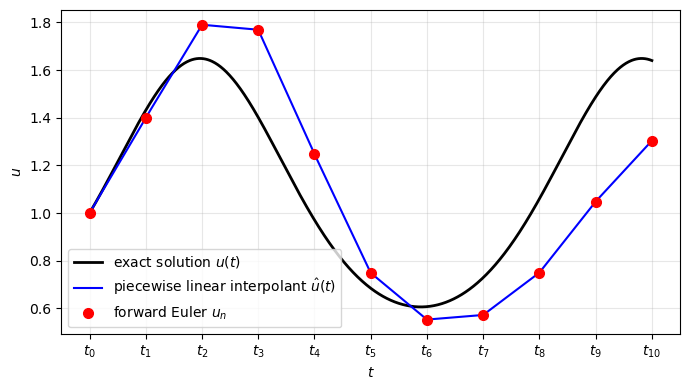

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_fine, u_exact(t_fine), 'k-', lw=2, label=r'exact solution $u(t)$')
ax.plot(t_fine, u_hat, 'b-', lw=1.5, label=r'piecewise linear interpolant $\hat{u}(t)$')
ax.plot(t_grid, u, 'o', color='red', ms=7, zorder=3, label=r'forward Euler $u_n$')
ax.set_xlabel(r'$t$')
ax.set_ylabel(r'$u$')
ax.set_xticks(t_grid, [rf'$t_{{{n}}}$' for n in range(N + 1)])
ax.legend(loc='best')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('piecewise_linear_interpolant_demo.pdf', bbox_inches='tight')
plt.show()